# ARTI403 – Image Processing
## Lab 6: Frequency Domain – Assessment
### Name: Abdullah Alnaji
### ID: 2240007157
**Task:** Using the Cameraman image, apply the Sobel filters in the frequency domain and show the results.

**Idea (Convolution Theorem):** convolution in the spatial domain equals multiplication in the frequency domain:

$$g(x,y) = f(x,y) * h(x,y) \;\Longleftrightarrow\; G(u,v) = F(u,v)\,H(u,v)$$

So the steps are: (1) FFT of the image, (2) FFT of the zero-padded, centered Sobel kernel, (3) multiply, (4) inverse FFT.

### Step 0 – Imports

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from numpy.fft import fft2, ifft2, fftshift, ifftshift
from skimage import data
from skimage.transform import resize
from scipy.signal import convolve2d

### Step 1 – Load and resize the Cameraman image

Image shape: (256, 256) | min/max: 0.008465512696419247 0.9994933599059728


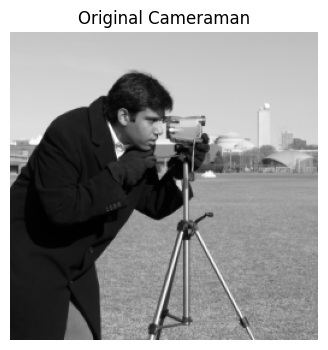

In [2]:
# Load cameraman image (already grayscale)
image = data.camera()
image = resize(image, (256, 256))   # Resize for faster FFT (values become floats in [0, 1])

M, N = image.shape
print("Image shape:", image.shape, "| min/max:", image.min(), image.max())

plt.figure(figsize=(4, 4))
plt.imshow(image, cmap='gray')
plt.title('Original Cameraman')
plt.axis('off')
plt.show()

### Step 2 – Define the Sobel filters

In [3]:
# Sobel filters
sobel_x = np.array([[-1, 0, 1],
                    [-2, 0, 2],
                    [-1, 0, 1]])

sobel_y = np.array([[-1, -2, -1],
                    [ 0,  0,  0],
                    [ 1,  2,  1]])

### Step 3 – Embed the kernel at the image center and take its FFT
The 3×3 kernel must be zero-padded to the image size (256×256) so both FFTs have the same shape. The kernel is placed at the center, then `ifftshift` moves its center to index (0, 0) before the FFT so no spatial shift is introduced in the output.

In [4]:
# Proper padding and centering of kernel in spatial domain
def center_embed_kernel(kernel, shape):
    padded = np.zeros(shape)
    kh, kw = kernel.shape
    ph, pw = shape

    # Find center coordinates
    cy, cx = ph // 2, pw // 2

    # Insert kernel centered at the image center
    padded[cy - kh//2:cy - kh//2 + kh, cx - kw//2:cx - kw//2 + kw] = kernel

    return fft2(ifftshift(padded))  # Shift before FFT to place (0,0) at top-left

### Step 4 – Compute the FFT of the image and of the Sobel filters

In [5]:
# FFT of the image
F = fft2(image)

# FFT of centered Sobel filters (use the provided function)
H_x = center_embed_kernel(sobel_x, (M, N))
H_y = center_embed_kernel(sobel_y, (M, N))

### Step 5 – Multiply in the frequency domain and go back to the spatial domain

In [6]:
# Multiply in the frequency domain
G_x = F * H_x
G_y = F * H_y

# Inverse FFT to get the spatial result
gx = ifft2(G_x).real        # horizontal gradient  (responds to vertical edges)
gy = ifft2(G_y).real        # vertical gradient    (responds to horizontal edges)

# Gradient magnitude (combined edge strength)
magnitude = np.sqrt(gx**2 + gy**2)

### Step 6 – Plot the results

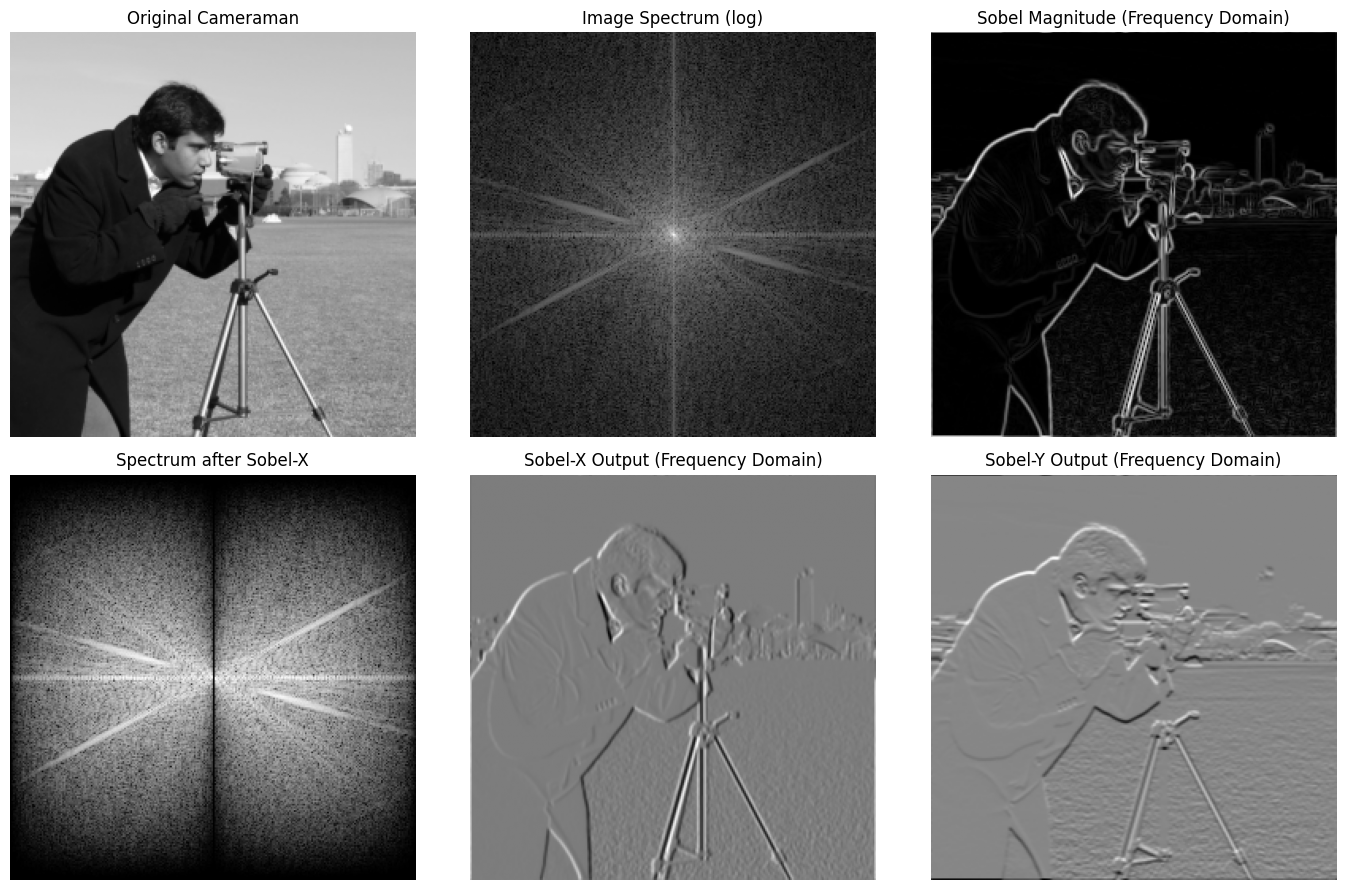

In [7]:
# Plot: image, filter spectra, spatial outputs
def spec(X):
    return np.log(1 + np.abs(fftshift(X)))

fig, axes = plt.subplots(2, 3, figsize=(14, 9))

axes[0, 0].imshow(image, cmap='gray');            axes[0, 0].set_title('Original Cameraman')
axes[0, 1].imshow(spec(F), cmap='gray');          axes[0, 1].set_title('Image Spectrum (log)')
axes[0, 2].imshow(magnitude, cmap='gray');        axes[0, 2].set_title('Sobel Magnitude (Frequency Domain)')

axes[1, 0].imshow(spec(G_x), cmap='gray');        axes[1, 0].set_title('Spectrum after Sobel-X')
axes[1, 1].imshow(gx, cmap='gray');               axes[1, 1].set_title('Sobel-X Output (Frequency Domain)')
axes[1, 2].imshow(gy, cmap='gray');               axes[1, 2].set_title('Sobel-Y Output (Frequency Domain)')

for ax in axes.ravel():
    ax.axis('off')
plt.tight_layout()
plt.savefig('sobel_frequency_domain_results.png', dpi=150)
plt.show()

### Extra – Frequency response of the Sobel filters
The Sobel filters are **high-pass in one direction** (derivative) and **low-pass (smoothing) in the other**. The plots below show $|H(u,v)|$ (centered): Sobel-X has a dark vertical centre band (zero response where there is no horizontal variation), and Sobel-Y has a dark horizontal centre band.

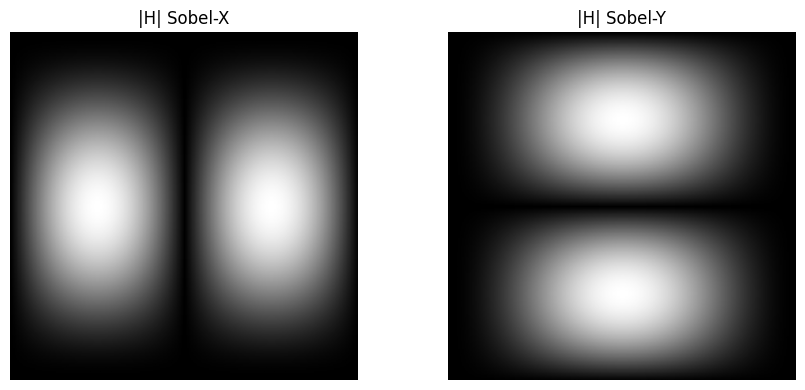

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(9, 4))
axes[0].imshow(fftshift(np.abs(H_x)), cmap='gray'); axes[0].set_title('|H| Sobel-X')
axes[1].imshow(fftshift(np.abs(H_y)), cmap='gray'); axes[1].set_title('|H| Sobel-Y')
for ax in axes: ax.axis('off')
plt.tight_layout()
plt.savefig('sobel_filter_spectra.png', dpi=150)
plt.show()

### Verification – compare with spatial-domain convolution
The result of the frequency-domain filtering should match spatial convolution with circular (wrap-around) boundaries, since the DFT assumes a periodic image.

In [9]:
gx_spatial = convolve2d(image, sobel_x, mode='same', boundary='wrap')
gy_spatial = convolve2d(image, sobel_y, mode='same', boundary='wrap')

print("Max abs difference (Sobel-X):", np.max(np.abs(gx - gx_spatial)))
print("Max abs difference (Sobel-Y):", np.max(np.abs(gy - gy_spatial)))
print("Match:", np.allclose(gx, gx_spatial) and np.allclose(gy, gy_spatial))

Max abs difference (Sobel-X): 1.7763568394002505e-15
Max abs difference (Sobel-Y): 2.8622937353617317e-15
Match: True
